# 03 — Hit Tahmini: Bir şarkının sesi, popüler olup olmayacağını söyler mi?

Keşif notebook'unda ses özellikleriyle popülerlik arasındaki korelasyonun çok zayıf olduğunu görmüştük (en fazla |0.13|). Bu notebook'ta soruyu doğrudan soruyoruz:

1. **Sadece ses özellikleriyle** popülerlik ne kadar tahmin edilebilir?
2. İşin içine **tür** ve **sanatçı** bilgisi girince ne değişiyor?
3. Bir şarkıyı popüler yapan şey gerçekte ne?

İki görev var: popülerlik puanını (0–100) tahmin etmek (**regresyon**) ve şarkının "hit" olup olmadığını tahmin etmek (**sınıflandırma**).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (average_precision_score, mean_absolute_error,
                             precision_recall_curve, r2_score, roc_auc_score)
from sklearn.model_selection import train_test_split

sys.path.append(str(Path.cwd().parent))
from src.ozellikler import HIT_ESIGI, ana_sanatci, sanatci_kodla, surumleri_birlestir
from src.veri import SES_OZELLIKLERI, temizle, tekil_sarkilar, veri_yukle

FIGURLER = Path.cwd().parent / "figures"
RASTGELE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 1. Popülerliği 0 olan şarkılar ve sürüm sorunu

Keşifte şarkıların %10.5'inin popülerliğinin tam 0 olduğunu görmüştük. Bunların bir kısmı gerçekten hiç dinlenmeyen şarkılar. Ama bir kısmının sebebi başka: Spotify aynı şarkının **single, albüm ve derleme sürümlerini ayrı ayrı puanlıyor**, dinlenmeler de çoğunlukla tek bir sürümde toplanıyor.

In [2]:
sarkilar = tekil_sarkilar(temizle(veri_yukle()))
anahtar = sarkilar["artists"].str.lower() + "|" + sarkilar["track_name"].str.lower()
sarkilar["surum_sayisi"] = anahtar.map(anahtar.value_counts())

sifir = sarkilar[sarkilar["popularity"] == 0]
print(f"Popülerliği 0 olan şarkı: {len(sifir):,}")
print(f"  bunların aynı sanatçı + aynı adla başka sürümü olanlar: %{(sifir['surum_sayisi'] > 1).mean()*100:.0f}")
print(f"Tüm şarkılarda bu oran: %{(sarkilar['surum_sayisi'] > 1).mean()*100:.0f}")

Popülerliği 0 olan şarkı: 9,443
  bunların aynı sanatçı + aynı adla başka sürümü olanlar: %58
Tüm şarkılarda bu oran: %15


In [3]:
# Örnek: aynı şarkının sürümleri
ornek = anahtar[(sarkilar["popularity"] == 0) & (sarkilar["surum_sayisi"] >= 3)].iloc[0]
sarkilar.loc[anahtar == ornek, ["track_name", "artists", "album_name", "popularity", "danceability", "energy"]]

,track_name,artists,album_name,popularity,danceability,energy
26,Winter Wonderland,Jason Mraz,Holly Jolly Christmas,0,0.62,0.309
28,Winter Wonderland,Jason Mraz,Christmas Time,0,0.62,0.309
29,Winter Wonderland,Jason Mraz,Perfect Christmas Hits,0,0.62,0.309
30,Winter Wonderland,Jason Mraz,Merry Christmas,0,0.62,0.309
31,Winter Wonderland,Jason Mraz,Christmas Music - Holiday Hits,0,0.62,0.309


Aynı ses özelliklerine sahip şarkı bir sürümde popüler, diğerinde 0. Bu satırları olduğu gibi bırakırsak iki sorun çıkar:
- Model aynı sesi hem "hit" hem "0" olarak görür ve kafası karışır.
- Neredeyse aynı satırlar eğitim ve test verisine bölünür. Model ezberleyerek olduğundan başarılı görünür (**veri sızıntısı**).

**Karar:** Her şarkının yalnızca en popüler sürümünü tutuyoruz (`surumleri_birlestir`).

In [4]:
veri = surumleri_birlestir(sarkilar.drop(columns="surum_sayisi"))
print(f"Birleştirme öncesi: {len(sarkilar):,} → sonrası: {len(veri):,} şarkı")
print(f"Popülerliği 0 olan oran: %{(sarkilar['popularity'] == 0).mean()*100:.1f} → %{(veri['popularity'] == 0).mean()*100:.1f}")

Birleştirme öncesi: 89,578 → sonrası: 81,056 şarkı
Popülerliği 0 olan oran: %10.5 → %5.9


## 2. Hedef değişken ve "hit" tanımı

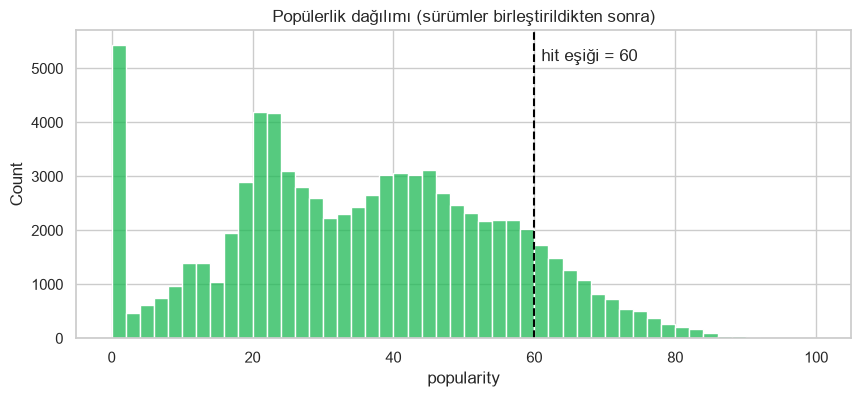

Hit oranı (popülerlik ≥ 60): %11.6


In [5]:
fig, eksen = plt.subplots(figsize=(10, 4))
sns.histplot(veri["popularity"], bins=50, color="#1DB954", ax=eksen)
eksen.axvline(HIT_ESIGI, ls="--", color="black")
eksen.text(HIT_ESIGI + 1, eksen.get_ylim()[1] * 0.9, f"hit eşiği = {HIT_ESIGI}")
eksen.set_title("Popülerlik dağılımı (sürümler birleştirildikten sonra)")
plt.show()

print(f"Hit oranı (popülerlik ≥ {HIT_ESIGI}): %{(veri['popularity'] >= HIT_ESIGI).mean()*100:.1f}")

Popülerliği **60 ve üzeri** olan şarkıları "hit" sayıyoruz. Bu, veri setinin yaklaşık en üst %12'lik dilimi. Sınıflar dengesiz: Rastgele bir şarkının hit olma ihtimali %12. Bu yüzden sınıflandırmada doğruluk (accuracy) yerine **ROC-AUC** ve **PR-AUC (average precision)** kullanacağız. Her şeye "hit değil" diyen bir model bile %88 doğruluk alırdı.

## 3. Özellikler ve eğitim/test ayrımı

Üç özellik grubunu karşılaştıracağız:

| Grup | İçerik |
|---|---|
| **Ses** | 9 ses özelliği + süre, explicit, ton (key), majör/minör (mode), ölçü |
| **Tür** | Şarkının Spotify tür etiketi (114 kategori) |
| **Sanatçı** | Sanatçının *diğer* şarkılarının ortalama popülerliği |

Sanatçı özelliği dikkat ister, çünkü hedef değişkenden üretiliyor. Yanlış hesaplanırsa model cevabı görür. Bu yüzden:
- Önce veri eğitim (%80) ve test (%20) olarak ayrılıyor. Test şarkılarının popülerliği hiçbir özelliğe karışmıyor.
- Eğitim verisi kendi içinde 5 katlı kodlanıyor. Bir şarkının kendi popülerliği kendi özelliğine girmiyor.
- Az şarkısı olan sanatçıların ortalaması genel ortalamaya doğru çekiliyor. Eğitimde hiç görülmemiş sanatçılar genel ortalamayı alıyor.

In [6]:
veri["explicit"] = veri["explicit"].astype(int)
veri["ana_sanatci"] = ana_sanatci(veri)
veri["tur"] = veri["track_genre"].astype("category")

SES = SES_OZELLIKLERI + ["duration_ms", "explicit", "key", "mode", "time_signature"]

egitim, test = train_test_split(veri, test_size=0.2, random_state=RASTGELE)
egitim, test = egitim.copy(), test.copy()
egitim["sanatci_pop"], test["sanatci_pop"] = sanatci_kodla(egitim, test)

y_egitim, y_test = egitim["popularity"], test["popularity"]
hit_egitim, hit_test = y_egitim >= HIT_ESIGI, y_test >= HIT_ESIGI

print(f"Eğitim: {len(egitim):,}  Test: {len(test):,}")
print(f"Test şarkılarının sanatçısı eğitimde de var: %{test['ana_sanatci'].isin(egitim['ana_sanatci']).mean()*100:.0f}")

Eğitim: 64,844  Test: 16,212
Test şarkılarının sanatçısı eğitimde de var: %89


## 4. Regresyon: popülerlik puanını tahmin etmek

Model olarak **HistGradientBoosting** kullanıyoruz: hızlı, doğrusal olmayan ilişkileri yakalayabiliyor ve tür gibi kategorik değişkenleri doğrudan işleyebiliyor. Karşılaştırma için iki basit taban çizgisi var:
- **Dummy:** Her şarkıya eğitim ortalamasını tahmin eder.
- **Doğrusal regresyon:** Sadece ses özellikleriyle.

In [7]:
OZELLIK_SETLERI = {
    "Ses": SES,
    "Ses + tür": SES + ["tur"],
    "Ses + tür + sanatçı": SES + ["tur", "sanatci_pop"],
}

def hgb(tip):
    # "from_dtype": category tipindeki sütunlar (tür) kategorik olarak işlenir
    return tip(random_state=RASTGELE, categorical_features="from_dtype")

sonuc = []
for ad, model in [("Dummy (ortalama)", DummyRegressor()), ("Doğrusal regresyon (ses)", LinearRegression())]:
    tahmin = model.fit(egitim[SES], y_egitim).predict(test[SES])
    sonuc.append({"model": ad, "R²": r2_score(y_test, tahmin), "MAE": mean_absolute_error(y_test, tahmin)})

regresyon_modelleri = {}
for ad, sutunlar in OZELLIK_SETLERI.items():
    model = hgb(HistGradientBoostingRegressor).fit(egitim[sutunlar], y_egitim)
    tahmin = model.predict(test[sutunlar])
    regresyon_modelleri[ad] = model
    sonuc.append({"model": f"Gradient boosting ({ad.lower()})", "R²": r2_score(y_test, tahmin),
                  "MAE": mean_absolute_error(y_test, tahmin)})

sonuc = pd.DataFrame(sonuc).set_index("model")
sonuc.round(3)

,R²,MAE
model,,
Dummy (ortalama),-0.000,15.976
Doğrusal regresyon (ses),0.058,15.296
Gradient boosting (ses),0.166,13.931
Gradient boosting (ses + tür),0.449,9.860
Gradient boosting (ses + tür + sanatçı),0.603,7.664


- **R²:** Popülerlikteki çeşitliliğin ne kadarının açıklandığı (0 = hiç, 1 = tamamı).
- **MAE:** Tahminin ortalama kaç puan saptığı (0–100 ölçeğinde).

**Yorum:**
- **Sadece sesle** en iyi model popülerlikteki çeşitliliğin yalnızca **%17**'sini açıklıyor. Doğrusal model %6'da kalıyor, yani sesin etkisi az ve doğrusal değil.
- **Tür** eklenince R² **0.45**'e çıkıyor.
- **Sanatçı** eklenince **0.60**'a çıkıyor ve ortalama hata 16 puandan 7.7 puana iniyor.

## 5. Sınıflandırma: hit mi, değil mi?

In [8]:
siniflandiricilar, olasiliklar, sinif_sonuc = {}, {}, []
for ad, sutunlar in OZELLIK_SETLERI.items():
    model = hgb(HistGradientBoostingClassifier).fit(egitim[sutunlar], hit_egitim)
    p = model.predict_proba(test[sutunlar])[:, 1]
    siniflandiricilar[ad], olasiliklar[ad] = model, p

    # Modelin en çok "hit" dediği %10'luk dilimde gerçekten hit olanların oranı
    ust_dilim = p >= np.quantile(p, 0.9)
    sinif_sonuc.append({
        "özellikler": ad,
        "ROC-AUC": roc_auc_score(hit_test, p),
        "PR-AUC": average_precision_score(hit_test, p),
        "en üst %10'da hit oranı": hit_test[ust_dilim].mean(),
    })

sinif_sonuc = pd.DataFrame(sinif_sonuc).set_index("özellikler")
print(f"Taban çizgisi (rastgele şarkının hit olma oranı): %{hit_test.mean()*100:.1f}")
sinif_sonuc.round(3)

Taban çizgisi (rastgele şarkının hit olma oranı): %11.5


,ROC-AUC,PR-AUC,en üst %10'da hit oranı
özellikler,,,
Ses,0.739,0.255,0.307
Ses + tür,0.894,0.539,0.552
Ses + tür + sanatçı,0.926,0.665,0.649


**Yorum:** Rastgele bir şarkının hit olma ihtimali %11.5. Sadece sese bakan model en emin olduğu %10'luk dilimde bu oranı **%31**'e çıkarıyor. Tesadüften iyi ama "hit formülü" denecek kadar değil. Tür ve sanatçı bilgisiyle bu oran **%65**'e çıkıyor.

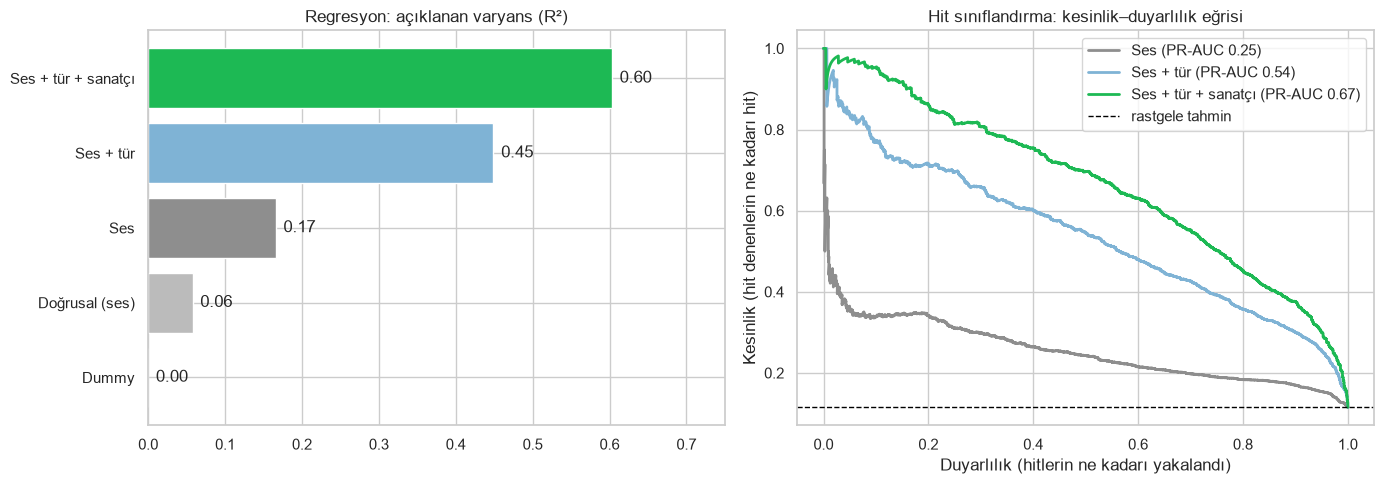

In [9]:
fig, (e1, e2) = plt.subplots(1, 2, figsize=(14, 5))
renkler = {"Ses": "#8E8E8E", "Ses + tür": "#7FB3D5", "Ses + tür + sanatçı": "#1DB954"}

r2 = sonuc["R²"].clip(lower=0)
r2.index = ["Dummy", "Doğrusal (ses)", "Ses", "Ses + tür", "Ses + tür + sanatçı"]
e1.barh(r2.index, r2.values, color=["#DDDDDD", "#BBBBBB"] + list(renkler.values()))
for i, v in enumerate(r2.values):
    e1.text(v + 0.01, i, f"{v:.2f}", va="center")
e1.set_xlim(0, 0.75)
e1.set_title("Regresyon: açıklanan varyans (R²)")

for ad, p in olasiliklar.items():
    kesinlik, duyarlilik, _ = precision_recall_curve(hit_test, p)
    e2.plot(duyarlilik, kesinlik, color=renkler[ad], lw=2,
            label=f"{ad} (PR-AUC {sinif_sonuc.loc[ad, 'PR-AUC']:.2f})")
e2.axhline(hit_test.mean(), ls="--", color="black", lw=1, label="rastgele tahmin")
e2.set_xlabel("Duyarlılık (hitlerin ne kadarı yakalandı)")
e2.set_ylabel("Kesinlik (hit denenlerin ne kadarı hit)")
e2.set_title("Hit sınıflandırma: kesinlik–duyarlılık eğrisi")
e2.legend()
fig.tight_layout()
fig.savefig(FIGURLER / "03_model_karsilastirma.png", dpi=120)
plt.show()

## 6. Popülerliği ne belirliyor?

### 6.1 Tüm özelliklerle: permütasyon önemi

Bir özelliğin değerleri test verisinde rastgele karıştırıldığında modelin R² skoru ne kadar düşüyor? Çok düşüyorsa model o özelliğe çok dayanıyor demektir.

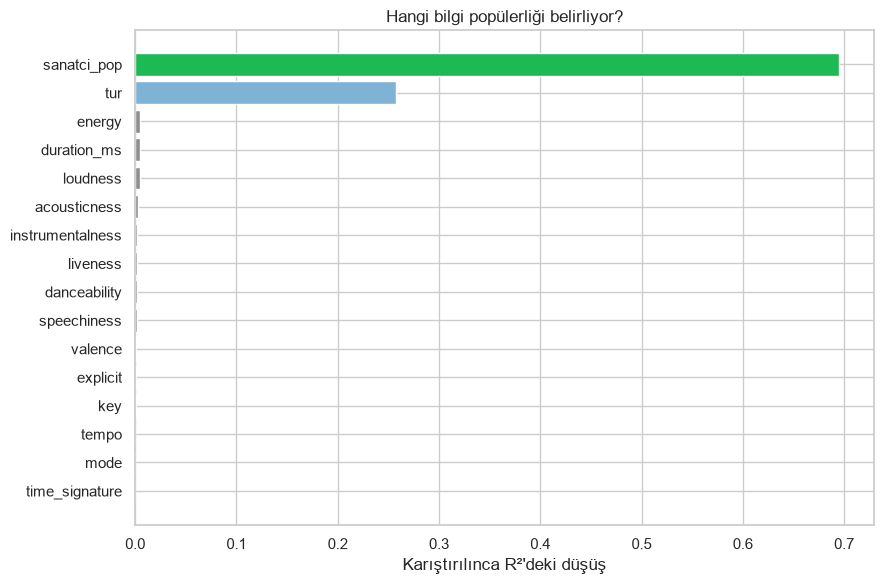

sanatci_pop     0.695
tur             0.258
energy          0.005
duration_ms     0.005
loudness        0.005
acousticness    0.003
dtype: float64

In [10]:
tam = OZELLIK_SETLERI["Ses + tür + sanatçı"]
onem = permutation_importance(regresyon_modelleri["Ses + tür + sanatçı"], test[tam], y_test,
                              n_repeats=5, random_state=RASTGELE, scoring="r2")
onem = pd.Series(onem.importances_mean, index=tam).sort_values()

fig, eksen = plt.subplots(figsize=(9, 6))
renk = ["#1DB954" if o == "sanatci_pop" else "#7FB3D5" if o == "tur" else "#8E8E8E" for o in onem.index]
eksen.barh(onem.index, onem.values, color=renk)
eksen.set_xlabel("Karıştırılınca R²'deki düşüş")
eksen.set_title("Hangi bilgi popülerliği belirliyor?")
fig.tight_layout()
fig.savefig(FIGURLER / "03_ozellik_onemi.png", dpi=120)
plt.show()
onem.sort_values(ascending=False).round(3).head(6)

**Yorum:** Sanatçı ve tür bilinince ses özelliklerinin modele katkısı **neredeyse sıfıra** iniyor. Sesin popülerlikle olan zayıf ilişkisinin büyük kısmı zaten türün içinde saklı. Örneğin metal hem sert ses hem düşük popülerlik demek.

### 6.2 Sadece ses: hangi ses özellikleri ve nasıl?

Sesin tek başına zayıf bir etkisi var ama sıfır değil. Ses modelinin en çok dayandığı özelliklere ve bu özelliklerin tahmini nasıl değiştirdiğine (**kısmi bağımlılık**) bakalım.

In [11]:
ses_onem = permutation_importance(regresyon_modelleri["Ses"], test[SES], y_test,
                                  n_repeats=5, random_state=RASTGELE, scoring="r2")
ses_onem = pd.Series(ses_onem.importances_mean, index=SES).sort_values(ascending=False)
ses_onem.round(3).head(6)

instrumentalness    0.082
acousticness        0.077
loudness            0.039
energy              0.036
valence             0.034
duration_ms         0.034
dtype: float64

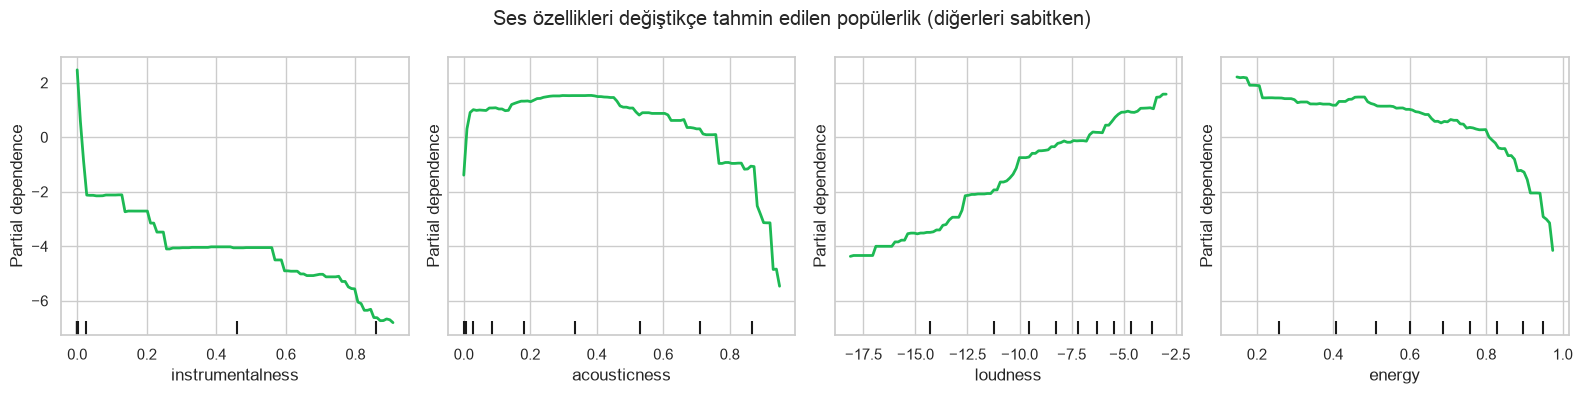

In [12]:
en_onemli = ses_onem.index[:4].tolist()
fig, eksenler = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
PartialDependenceDisplay.from_estimator(
    regresyon_modelleri["Ses"], test[SES].sample(3000, random_state=RASTGELE), en_onemli,
    ax=eksenler, line_kw={"color": "#1DB954", "lw": 2})
fig.suptitle("Ses özellikleri değiştikçe tahmin edilen popülerlik (diğerleri sabitken)")
fig.tight_layout()
fig.savefig(FIGURLER / "03_ses_etkisi.png", dpi=120)
plt.show()

**Yorum** (y ekseni: ortalamaya göre tahmindeki puan değişimi):
- **Sözsüz parçalar** (instrumentalness yüksek) vokalli şarkılara göre ~9 puan daha düşük popülerlik tahmini alıyor. Dinleyiciler vokal istiyor.
- **Çok akustik** (>0.8) ve **aşırı enerjik** (>0.8) şarkılar cezalandırılıyor. Popüler müzik orta bölgede.
- **Yüksek ses** (loudness) popülerlikle birlikte artıyor. Bu, modern pop prodüksiyonunun "loudness war" etkisiyle uyumlu.
- Tüm bu etkiler birkaç puan düzeyinde. 0–100'lük ölçekte sesin popülerliği ancak hafifçe ittiğini gösteriyor.

## 7. Hiç görülmemiş sanatçılar: model yeni bir sanatçıyı tahmin edebilir mi?

In [13]:
yeni = (~test["ana_sanatci"].isin(egitim["ana_sanatci"])).to_numpy()
tahmin_tam = regresyon_modelleri["Ses + tür + sanatçı"].predict(test[tam])
tahmin_tur = regresyon_modelleri["Ses + tür"].predict(test[OZELLIK_SETLERI["Ses + tür"]])

pd.DataFrame({
    "şarkı sayısı": [(~yeni).sum(), yeni.sum()],
    "R² (ses + tür)": [r2_score(y_test[~yeni], tahmin_tur[~yeni]), r2_score(y_test[yeni], tahmin_tur[yeni])],
    "R² (ses + tür + sanatçı)": [r2_score(y_test[~yeni], tahmin_tam[~yeni]), r2_score(y_test[yeni], tahmin_tam[yeni])],
}, index=["Sanatçı eğitimde var", "Yeni sanatçı"]).round(3)

,şarkı sayısı,R² (ses + tür),R² (ses + tür + sanatçı)
Sanatçı eğitimde var,14358,0.460,0.627
Yeni sanatçı,1854,0.332,0.374


**Yorum:** Sanatçı özelliği en çok bilinen sanatçılarda işe yarıyor. Yeni sanatçılarda (test şarkılarının %11'i) R² 0.37'ye düşüyor. Bu, gerçek hayattaki "yeni çıkan bir sanatçının şarkısı tutar mı?" sorusunun neden zor olduğunu da gösteriyor.

## 8. Sürpriz hitler: modelin en çok yanıldığı şarkılar

In [14]:
test["tahmin"] = tahmin_tam
test["hata"] = test["popularity"] - test["tahmin"]
(test.nlargest(10, "hata")
 [["track_name", "artists", "track_genre", "popularity", "tahmin", "sanatci_pop"]]
 .round(1))

,track_name,artists,track_genre,popularity,tahmin,sanatci_pop
120,First Class,Jack Harlow,hip-hop,86,6.4,21.5
226,Love Yourself,Justin Bieber,pop,84,10.7,20.9
210,Envolver,Anitta,funk,84,10.9,18.3
75,Bad Habits,Ed Sheeran,pop,88,15.5,27.5
416,Cool for the Summer,Demi Lovato,dance,81,8.9,22.3
180,House of Memories,Panic! At The Disco,rock,85,14.9,22.9
1219,BICHOTA,KAROL G,reggae,76,7.4,23.3
669,My Girl,The Temptations,funk,79,11.0,14.8
1032,I Want You Back,The Jackson 5,soul,77,9.7,12.8
128,Shape of You,Ed Sheeran,pop,86,19.1,27.5


**Yorum: Veri setinin bir sınırlılığı ortaya çıkıyor.** Listedeki sürpriz hitlerin çoğu aslında çok ünlü sanatçılara ait: Ed Sheeran, Justin Bieber, Jack Harlow. Model bu şarkıları neden düşük tahmin etti? Çünkü bu sanatçıların veri setindeki diğer şarkılarının çoğu **derleme albümlerden** ("Today's Party Hits", "Autumn Vibes 2022" gibi) alınmış ve popülerlikleri 0. Örneğin Ed Sheeran'ın 15 şarkısından 8'i 0 puanlı. Spotify derleme kopyalarına neredeyse hiç puan vermiyor. Orijinal sürüm veri setinde yoksa, sürüm birleştirme de bunu düzeltemiyor.

Sonuç olarak `sanatci_pop` bu sanatçılar için olduğundan düşük kalıyor. Daha temiz bir sanatçı popülerliği (örneğin Spotify'ın kendi sanatçı popülerlik puanı ya da dinleyici sayısı) modeli muhtemelen daha da iyileştirirdi.

## 9. Özet

**Ana bulgu: Bir şarkının popülerliğini "nasıl ses çıkardığı" değil, "kim tarafından, hangi türde" yapıldığı belirliyor.**

| Bilgi | R² | Hit PR-AUC |
|---|---|---|
| Sadece ses | 0.17 | 0.255 |
| + tür | 0.45 | 0.539 |
| + sanatçı | 0.60 | 0.665 |

- **Sesin etkisi gerçek ama küçük:** Vokalli, akustik olmayan, yüksek sesli ve aşırı enerjik olmayan şarkılar biraz daha popüler. Etkiler birkaç puan düzeyinde.
- **Tür bilgisinin önemli kısmı veri setinin yapısından geliyor:** Her türden 1.000 şarkı alınmış. Bazı türler (k-pop, pop-film) Spotify'ın popüler listelerinden, bazıları (iranian, romance) az dinlenen kataloglardan gelmiş olabilir. Bu yüzden "tür" etkisi kısmen gerçek dinleyici tercihini, kısmen de verinin nasıl toplandığını yansıtıyor.
- **Veri temizliği sonucu doğrudan etkiliyor:** Aynı şarkının sürümleri birleştirilmeseydi popülerliği 0 olan şarkı oranı %10.5 olarak kalacaktı (birleştirmeyle %5.9'a indi) ve neredeyse aynı şarkılar eğitim ile test arasında bölünecekti.
- **Sınırlılık:** Derleme albüm kopyaları, ünlü sanatçıların ortalama popülerliğini aşağı çekiyor. Sürpriz hitlerin çoğu bu yüzden oluşuyor.

**Sonraki adım:** `04_benzer_sarki.ipynb` — ses özelliklerine göre benzer şarkı bulucu.